In [ ]:
import os
import sys

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_12/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# 12.2. TSMixer: а нужен ли трансформер

Патчинг вернул трансформер в игру, но выигрыш дало не внимание, а то, что подаётся на вход.
Сколько нелинейности нужно сверх одной линейной матрицы и нужно ли смешивать каналы?

TSMixer (Chen et al., 2023) отвечает «почти никакой». В модели нет ни внимания, ни свёрток — только
полносвязные слои, которые по очереди перемешивают окно по времени и по каналам. Тот же приём, что
в MLP-Mixer для изображений: два направления смешивания вместо придуманного механизма связей.

Разбираем:
- окно как матрица `L × C` — впервые панель подаётся целиком;
- temporal и feature mixing, и почему DLinear — это TSMixer без них;
- опыт: испортить шесть каналов и посмотреть, сдвинется ли прогноз седьмого;
- `TSMixerx`: ковариаты как дополнительные каналы.

In [1]:
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasetsforecast.long_horizon import LongHorizon
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from neuralforecast import NeuralForecast
from neuralforecast.models import DLinear, PatchTST, TSMixer, TSMixerx
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, mape

warnings.simplefilter("ignore")
for name in ["pytorch_lightning", "lightning", "lightning.pytorch", "lightning_fabric"]:
    logging.getLogger(name).setLevel(logging.ERROR)
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

SEED = 1
ACCELERATOR = "gpu" if torch.cuda.is_available() else "cpu"
TRAINER_KW = dict(accelerator=ACCELERATOR, enable_progress_bar=True, enable_model_summary=False, logger=False)

In [2]:
def score(cv):
    """MAE и MAPE каждой модели, усреднённые по окнам кросс-валидации."""
    models = [c for c in cv.columns if c not in ("unique_id", "ds", "cutoff", "y")]
    res = evaluate(cv, metrics=[mae, mape], models=models)
    return res.groupby("metric")[models].mean().T.round({"mae": 3, "mape": 4}).sort_values("mae")


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def box(ax, x, y, w, h, text, fc="#eef3fb", fs=9):
    """Прямоугольник со скруглёнными углами и подписью — для схем архитектур."""
    ax.add_patch(
        FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec="#3b5bdb", lw=1.2)
    )
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, linespacing=1.35)


def arrow(ax, xy_from, xy_to, color="#495057"):
    ax.add_patch(
        FancyArrowPatch(xy_from, xy_to, arrowstyle="-|>", mutation_scale=11, lw=1.1, color=color, shrinkA=0, shrinkB=0)
    )

## Данные и постановка

Те же, что в 12.1: ETTm2, `h=96`, `input_size=336`, три окна и фиксированный бюджет обучения — `100` шагов
для линейных моделей и `300` для нейросетевых.

In [3]:
Y_df, _, _ = LongHorizon.load(directory="../data", group="ETTm2")
Y_df["ds"] = pd.to_datetime(Y_df["ds"])

H, L, N_WINDOWS, LR = 96, 336, 3, 1e-3
LINEAR_STEPS, NEURAL_STEPS = 100, 300
N_SERIES = Y_df["unique_id"].nunique()
DROP = 0.1  # библиотечное значение по умолчанию 0.9 на таком бюджете не даёт модели ничего выучить

common = dict(h=H, input_size=L, learning_rate=LR, random_seed=SEED, **TRAINER_KW)
linear_kw = {**common, "max_steps": LINEAR_STEPS}
neural_kw = {**common, "max_steps": NEURAL_STEPS}

## 1. Окно как матрица

До сих пор каждый ряд жил своей жизнью: модель получала вектор длины `L` и не знала, что рядом есть ещё
шесть векторов. TSMixer получает их сразу — матрицей `L × C`, где строки это моменты времени, а столбцы
это каналы.

In [4]:
tail = Y_df[Y_df["ds"] >= Y_df["ds"].max() - pd.Timedelta(minutes=15 * (L - 1))]
matrix = tail.pivot(index="ds", columns="unique_id", values="y")
print("матрица окна:", matrix.shape)

матрица окна: (336, 7)


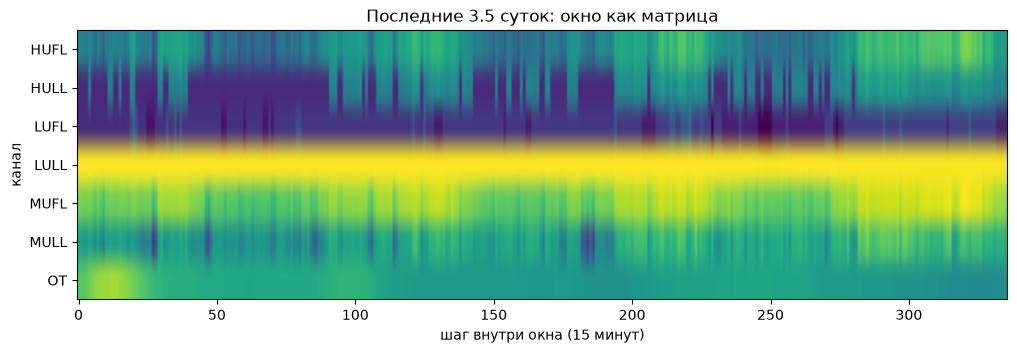

In [5]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.imshow(matrix.T.to_numpy(), aspect="auto", cmap="viridis")
ax.set(yticks=range(N_SERIES), yticklabels=matrix.columns, xlabel="шаг внутри окна (15 минут)", ylabel="канал")
ax.set_title("Последние 3.5 суток: окно как матрица");
ax.grid(False)

Каждая строка этой картинки раньше была отдельным рядом, а теперь стала строкой общей матрицы. Вся разница
между моделями дальше — в том, разрешено ли им смотреть поперёк строк.

## 2. Устройство TSMixer

Блок состоит из двух MLP, каждый перемешивает свою ось:

- **temporal mixing** — линейный слой `L → L` внутри каждого канала: модель смотрит вдоль времени;
- **feature mixing** — MLP `C → ff_dim → C` внутри каждого момента: модель смешивает каналы.

Формально, для входа $X \in \mathbb{R}^{L \times C}$:

$$U = X + \mathrm{ReLU}\big(\mathrm{BN}(W_t X + b_t)\big), \qquad
  V = U + W_2\,\mathrm{ReLU}(W_1 U + b_1) + b_2 .$$

Обе операции не меняют размерность, поэтому блоки можно ставить друг на друга. После `n_block` блоков стоит
линейная проекция `L → H`, общая для всех каналов.

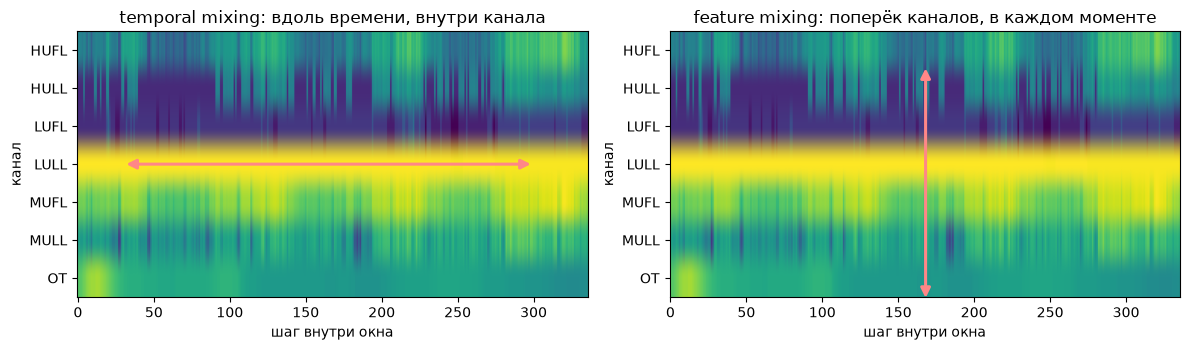

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax in axes:
    ax.imshow(matrix.T.to_numpy(), aspect="auto", cmap="viridis")
    ax.set(yticks=range(N_SERIES), yticklabels=matrix.columns, xlabel="шаг внутри окна", ylabel="канал")
    ax.grid(False)

axes[0].add_patch(FancyArrowPatch((30, 3), (300, 3), arrowstyle="<|-|>", mutation_scale=14, lw=2.2, color="#ff8787"))
axes[0].set_title("temporal mixing: вдоль времени, внутри канала")

axes[1].add_patch(FancyArrowPatch((168, 0.4), (168, 6.6), arrowstyle="<|-|>", mutation_scale=14, lw=2.2, color="#ff8787"))
axes[1].set_title("feature mixing: поперёк каналов, в каждом моменте")

plt.tight_layout();

Посмотрим на размерности в собранной модели.

In [7]:
demo = TSMixer(h=H, input_size=L, n_series=N_SERIES, dropout=DROP, **TRAINER_KW)

for i, layer in enumerate(demo.mixing_layers, 1):
    time_shape = tuple(layer.temporal_mixer.temporal_lin.weight.shape)
    chan_in = tuple(layer.feature_mixer.feature_lin_1.weight.shape)
    chan_out = tuple(layer.feature_mixer.feature_lin_2.weight.shape)
    print(f"блок {i}: время {time_shape[0]}→{time_shape[1]}, каналы {chan_in[1]}→{chan_in[0]}→{chan_out[0]}")

print("выходная проекция:", tuple(demo.out.weight.shape), "= L → H, общая для всех каналов")
print("параметров:", n_params(demo))

блок 1: время 336→336, каналы 7→64→7
блок 2: время 336→336, каналы 7→64→7
выходная проекция: (96, 336) = L → H, общая для всех каналов
параметров: 279580


Внутри блока размерности не меняются: временная матрица `336 × 336` живёт внутри каждого канала отдельно,
канальная `7 → 64 → 7` — внутри каждого из 336 моментов. И только в конце стоит общая проекция в горизонт.

Отсюда прямое следствие: **если убрать перемешивающие блоки, останется DLinear.** Та же матрица `L → H`,
применённая к каждому каналу отдельно. TSMixer — это DLinear плюс два слоя нелинейного перемешивания,
и вопрос в том, сколько эти слои добавляют.

## 3. Модели сравнения

DLinear — вырожденный TSMixer, с ним сравнение построчное. PatchTST — канально-независимый трансформер,
точка отсчёта «как выглядит модель без смешивания каналов».

In [8]:
t0 = time.time()
nf_dl = NeuralForecast(models=[DLinear(alias="DLinear", **linear_kw)], freq="15min")
cv_dl = nf_dl.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
time_dl = time.time() - t0
score(cv_dl)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

metric,mae,mape
DLinear,0.188,0.2524


In [9]:
t0 = time.time()
nf_pt = NeuralForecast(models=[PatchTST(alias="PatchTST", **neural_kw)], freq="15min")
cv_pt = nf_pt.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
time_pt = time.time() - t0
score(cv_pt)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

metric,mae,mape
PatchTST,0.206,0.2469


## 4. TSMixer

Та же постановка и те же окна. Отличие одно: `n_series=7`, модель получает матрицу `L × C` целиком.

In [10]:
t0 = time.time()
nf_tm = NeuralForecast(models=[TSMixer(alias="TSMixer", n_series=N_SERIES, dropout=DROP, **neural_kw)], freq="15min")
cv_tm = nf_tm.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
time_tm = time.time() - t0
score(cv_tm)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

metric,mae,mape
TSMixer,0.199,0.2555


In [11]:
summary = pd.concat([score(cv_dl), score(cv_pt), score(cv_tm)]).sort_values("mae")
summary["параметров"] = summary.index.map(
    {"DLinear": n_params(nf_dl.models[0]), "PatchTST": n_params(nf_pt.models[0]), "TSMixer": n_params(nf_tm.models[0])}
)
summary["обучение, с"] = summary.index.map({"DLinear": time_dl, "PatchTST": time_pt, "TSMixer": time_tm})
summary.round(2)

metric,mae,mape,параметров,"обучение, с"
DLinear,0.19,0.25,64704,5.17
TSMixer,0.20,0.26,279580,10.50
PatchTST,0.21,0.25,921187,21.27


Два слоя нелинейного перемешивания и в шесть раз больше параметров — а разница с DLinear в пределах сотых.
Чтобы понять, значима ли она, нужны три сида.

Время обучения в лоб сравнивать нельзя: у TSMixer по умолчанию `windows_batch_size=32`, у остальных 1024,
то есть за шаг он видит в тридцать раз меньше окон. Он делает меньше работы за шаг, а не больше работы
в единицу времени.

## 5. Смешивает ли модель каналы

Свойство надо измерить, а не принять на веру. Испортим историю шести рядов, оставив `OT` нетронутым,
и посмотрим, сдвинется ли прогноз для `OT`.

У канально-независимой модели сдвига быть не может: у неё нет общего веса между каналами. У TSMixer он
обязан быть — feature mixing смотрит поперёк столбцов на каждом шаге.

In [12]:
cutoff = cv_tm["cutoff"].max()
history = Y_df[Y_df["ds"] <= cutoff]

ruined = history.copy()
other = ruined["unique_id"] != "OT"
ruined.loc[other, "y"] = np.random.default_rng(0).permutation(ruined.loc[other, "y"].to_numpy())


def shift(nf, alias):
    """Насколько сдвигается прогноз OT, если историю остальных шести рядов перемешать."""
    clean = nf.predict(df=history).query("unique_id == 'OT'")[["ds", alias]]
    bad = nf.predict(df=ruined).query("unique_id == 'OT'")[["ds", alias]]
    both = clean.merge(bad, on="ds", suffixes=("_чисто", "_испорчено"))
    return (both[f"{alias}_чисто"] - both[f"{alias}_испорчено"]).abs().max()


pd.Series(
    {"PatchTST, каналы независимы": shift(nf_pt, "PatchTST"), "TSMixer, каналы смешаны": shift(nf_tm, "TSMixer")},
    name="макс. сдвиг прогноза OT",
).to_frame().round(3)

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

,макс. сдвиг прогноза OT
"PatchTST, каналы независимы",0.000
"TSMixer, каналы смешаны",0.039


Ноль у PatchTST и заметный сдвиг у TSMixer. Свойство измерено: одна модель не видит другие каналы, вторая
видит и реагирует.

Масштаб реакции стоит сравнить с ошибкой TSMixer на том же окне. Если сдвиг составляет её заметную долю, значит
модель опирается на каналы; если это малая часть — смешивание разрешено архитектурой, но данные его не требуют.

Семь рядов ETTm2 — датчики одного объекта, измеряющие разные величины. Предсказательная связь между ними
слабая. В статье на семи наборах средняя разница между полным TSMixer и версией без смешивания каналов
не достигает процента: смешивание окупается там, где каналы связаны по смыслу.

## 6. TSMixerx: ковариаты как ещё несколько каналов

В TSMixer экзогенных признаков нет. `TSMixerx` добавляет их не отдельной ветвью, а тем же способом, каким
устроено всё остальное: известные в будущем признаки становятся дополнительными каналами той же матрицы.
Feature mixing после этого смешивает `7 + число признаков` каналов.

Проверим на календарных признаках, которые для 15-минутного потребления обязаны быть полезны: час суток
и день недели.

In [13]:
exog_df = Y_df.assign(hour=Y_df["ds"].dt.hour, weekday=Y_df["ds"].dt.weekday)

t0 = time.time()
nf_tmx = NeuralForecast(
    models=[
        TSMixerx(
            alias="TSMixerx + календарь",
            n_series=N_SERIES,
            futr_exog_list=["hour", "weekday"],
            dropout=DROP,
            **neural_kw,
        )
    ],
    freq="15min",
)
cv_tmx = nf_tmx.cross_validation(df=exog_df, n_windows=N_WINDOWS, step_size=H)
time_tmx = time.time() - t0

pd.concat([score(cv_tm), score(cv_tmx)]).round(3)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

metric,mae,mape
TSMixer,0.199,0.256
TSMixerx + календарь,0.198,0.276


Признаки не помогли. Читать это надо аккуратно, потому что неверный вывод здесь возможен в обе стороны.

Неверно заключить, что календарь не нужен: для 15-минутного потребления час суток и день недели полезны
по построению. Другое объяснение — устройство модели: `TSMixerx` не отбирает признаки, а добавляет их каналами,
и два лишних канала удорожают задачу.

Отсюда вывод про архитектуру. У `TSMixerx` признак — ещё один канал той же матрицы: ни отдельной сети под
каждый тип входа, ни отбора переменных. Пока признаков десятки, этого хватает; когда их сотни и они
разнородны, нужен отбор — а это устройство другого класса моделей.

## 7. Где смешивание каналов окупается

На ETT его почти нет, и это свойство задачи, а не случайность набора: каналы измеряют разные величины,
и модель прекрасно живёт, обрабатывая их по отдельности.

Другое дело розница. В M5 нужно предсказать продажи тысяч товаров с общей структурой спроса — акции, праздники,
сезонность категории, — и информация о соседних товарах полезна напрямую. Числа там расходятся резко:
канально-независимые модели держатся около 1.0 WRMSSE, то есть на уровне наивного прогноза, а TSMixer
показывает 0.737.

Оговорка: это числа из чужих таблиц, победитель M5 показал 0.520, и напрямую сравнивать их с нашими нельзя —
разные наборы, метрики и бюджеты настройки. Вывод не «TSMixer лучше», а «смешивание каналов стоит того,
когда каналы связаны по смыслу».

### Для самостоятельного изучения

- **TMix-Only.** Убрать feature mixing и оставить только временное: в статье на семи наборах и четырёх
  горизонтах средняя разница с полным TSMixer не достигает процента. Отдельной ручки в neuralforecast нет,
  но TSMixer на одном ряду с `n_series=1` — это и есть TMix-Only: при одном канале feature mixing
  вырождается в тождественное отображение.
- **`n_block` и `ff_dim`.** Два блока и 64 — значения из статьи. Сколько блоков нужно на нашем ряде,
  решается сеткой, а не чтением.
- **`dropout`.** Мы взяли 0.1 вместо 0.9. Разница покажет, насколько результат зависит от регуляризации.
- **Три сида.** Разница между TSMixer и DLinear может оказаться меньше разброса по инициализациям.
- **`TimeMixer` и `TiDE`.** TimeMixer тоже `MULTIVARIATE = True`, но смешивает не каналы, а масштабы
  сезонности. TiDE — encoder-decoder без внимания, где декодер отвечает за реакцию на ковариаты.

## 8. Итоги

1. **Точечная токенизация — главная поломка трансформера на рядах.** Но лечит она не столько точность,
   сколько стоимость: патч уменьшает карту внимания на порядок, а качество на гладком ETTm2 не меняет.
2. **Ни внимание, ни смешивание каналов не дают выигрыша сами по себе.** PatchTST обошёл поточечный
   трансформер, TSMixer обошёл PatchTST, но оба раза на сотые, а DLinear впереди. Архитектура решает, что
   модель физически может делать; данные решают, что она из этого возьмёт.
3. **MLP без внимания конкурентоспособен,** когда данных мало и нелинейности в задаче почти нет.

Главное: TSMixer и DLinear — не два разных подхода, а одна модель и она же с двумя дополнительными слоями.

Дальше — другой класс задач: не «один ряд, известное прошлое, точечный прогноз», а разнотипные признаки
разной доступности и нужный интервал. Там на первый план выходит система подготовки входов, и её удобно
разбирать на TFT.